# Import models 

In [1]:
import os
import subprocess
import pandas as pd
import numpy as np
import optuna
from optuna.samplers import NSGAIIISampler
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import re

C:\Users\hp\anaconda3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Simulator running script

In [2]:
# =========================
# PATHS
# =========================
ECLRUN_EXE = r"C:\ecl\macros\eclrun.exe"
BASE_DIR = r"C:\Users\hp\Desktop\Eclipsetimesteps one year"

DATA_FILE_NAME = "Egg_Model_ECL.DATA"
RSM_FILE_NAME = "Egg_Model_ECL.RSM"
RSM_PATH = os.path.join(BASE_DIR, "EGG_MODEL_ECL.RSM")

N_BLOCKS = 10
BLOCK_END_DAYS = 360  # end of each block (24*30)
TARGET_TIMES = [BLOCK_END_DAYS * i for i in range(1, N_BLOCKS + 1)]
FINAL_TIME = TARGET_TIMES[-1]

In [3]:
# =========================
# RUN ECLIPSE
# =========================
def run_eclipse():
    print("▶ Running Eclipse ...")
    cmd = [ECLRUN_EXE, "eclipse", DATA_FILE_NAME]
    subprocess.run(cmd, cwd=BASE_DIR, check=True)
    print("✔ Eclipse finished")

# =========================
# EXTRACT FOPT & FWPT PER BLOCK
# =========================
def extract_FOPT_FWPT_from_RSM(rsm_path):

    with open(rsm_path, "r") as f:
        lines = f.readlines()

    inside_summary = False
    fopt_idx = fwpt_idx = None

    for line in lines:

        if "SUMMARY OF RUN" in line:
            inside_summary = True
            fopt_idx = fwpt_idx = None
            continue

        if not inside_summary:
            continue

        tokens = line.split()
        if not tokens:
            continue

        # Detect column headers
        if fopt_idx is None and "FOPT" in tokens and "FWPT" in tokens:
            fopt_idx = tokens.index("FOPT")
            fwpt_idx = tokens.index("FWPT")
            continue

        if fopt_idx is None:
            continue

        # ✅ Only data rows have numeric TIME
        if not tokens[0][0].isdigit():
            continue
        if float(tokens[0]) == 3600.0:
            return float(tokens[fopt_idx]), float(tokens[fwpt_idx])

In [4]:
def modify_data_per_control_block(blocks_params):

    data_path = os.path.join(BASE_DIR, DATA_FILE_NAME)

    with open(data_path, "r") as f:
        lines = f.readlines()

    block_pattern = re.compile(r"--\s*Block\s+(\d+)", re.IGNORECASE)

    current_block = None
    new_lines = []

    for line in lines:

        # Detect block number
        m = block_pattern.search(line)
        if m:
            current_block = int(m.group(1))
            new_lines.append(line)
            continue

        # Skip if block not in params
        if current_block is None or current_block > len(blocks_params):
            new_lines.append(line)
            continue

        params = blocks_params[current_block - 1]
        stripped = line.strip()

        # -------------------------
        # PRODUCER BHP
        # -------------------------
        prod_match = re.match(r"'PROD(\d+)'", stripped)
        if prod_match and "'BHP'" in stripped:

            prod_num = prod_match.group(1)
            key = f"BHP{prod_num}"

            if key in params:
                bhp_value = int(params[key])

                # Replace last numeric value in line (robust)
                line = re.sub(r"(5\*\s*)(\d+)", rf"\g<1>{bhp_value}", line)

        # -------------------------
        # INJECTOR RATE
        # -------------------------
        inj_match = re.match(r"'INJECT(\d+)'", stripped)
        if inj_match and "'RATE'" in stripped:

            inj_num = inj_match.group(1)
            key = f"inj_rate{inj_num}"

            if key in params:
                rate_value = int(params[key])

                # Replace RATE value robustly
                line = re.sub(r"('RATE'\s+)(\d+)", rf"\g<1>{rate_value}", line)

        new_lines.append(line)

    with open(data_path, "w") as f:
        f.writelines(new_lines)

# Define objective optimization function

In [5]:
def objective(trial):

    # 1) Suggest parameters per control block
    blocks_params = []
    for b in range(1, N_BLOCKS + 1):
        blocks_params.append({
            "BHP1": trial.suggest_int(f"BHP1_b{b}", 150, 390),
            "BHP2": trial.suggest_int(f"BHP2_b{b}", 150, 390),
            "BHP3": trial.suggest_int(f"BHP3_b{b}", 150, 390),
            "BHP4": trial.suggest_int(f"BHP4_b{b}", 150, 390),
            "inj_rate1": trial.suggest_int(f"inj_rate1_b{b}", 50, 400),
            "inj_rate2": trial.suggest_int(f"inj_rate2_b{b}", 50, 400),
            "inj_rate3": trial.suggest_int(f"inj_rate3_b{b}", 50, 400),
            "inj_rate4": trial.suggest_int(f"inj_rate4_b{b}", 50, 400),
            "inj_rate5": trial.suggest_int(f"inj_rate5_b{b}", 50, 400),
            "inj_rate6": trial.suggest_int(f"inj_rate6_b{b}", 50, 400),
            "inj_rate7": trial.suggest_int(f"inj_rate7_b{b}", 50, 400),
            "inj_rate8": trial.suggest_int(f"inj_rate8_b{b}", 50, 400),
        })

    # 2) Update schedule per CONTROL BLOCK (BHP + RATE)
    modify_data_per_control_block(blocks_params)

    run_eclipse()
    # 3) Extract FOPT/FWPT at block end times
    fopt, fwpt = extract_FOPT_FWPT_from_RSM(RSM_PATH)
    return fopt, fwpt

# Optimization running 

In [ ]:
sampler = optuna.samplers.TPESampler(
    n_startup_trials=42,
    multivariate=False,
    seed=42)

study = optuna.create_study(
    directions=["maximize", "minimize"],
    sampler=sampler,
    study_name="ECLIPSE_SUM_DELTA_FOPT_FWPT"
)

study.optimize(objective, n_trials=100, show_progress_bar=False)

[I 2026-11-07 22:51:55,528] A new study created in memory with name: ECLIPSE_SUM_DELTA_FOPT_FWPT


▶ Running Eclipse ...


[I 2026-11-07 22:53:55,721] Trial 0 finished with values: [546777.2, 5843704.0] and parameters: {'BHP1_b1': 240, 'BHP2_b1': 379, 'BHP3_b1': 326, 'BHP4_b1': 294, 'inj_rate1_b1': 104, 'inj_rate2_b1': 104, 'inj_rate3_b1': 70, 'inj_rate4_b1': 354, 'inj_rate5_b1': 260, 'inj_rate6_b1': 298, 'inj_rate7_b1': 57, 'inj_rate8_b1': 390, 'BHP1_b2': 350, 'BHP2_b2': 201, 'BHP3_b2': 193, 'BHP4_b2': 194, 'inj_rate1_b2': 156, 'inj_rate2_b2': 234, 'inj_rate3_b2': 201, 'inj_rate4_b2': 152, 'inj_rate5_b2': 264, 'inj_rate6_b2': 98, 'inj_rate7_b2': 152, 'inj_rate8_b2': 178, 'BHP1_b3': 259, 'BHP2_b3': 339, 'BHP3_b3': 198, 'BHP4_b3': 273, 'inj_rate1_b3': 257, 'inj_rate2_b3': 66, 'inj_rate3_b3': 263, 'inj_rate4_b3': 109, 'inj_rate5_b3': 72, 'inj_rate6_b3': 383, 'inj_rate7_b3': 388, 'inj_rate8_b3': 333, 'BHP1_b4': 223, 'BHP2_b4': 173, 'BHP3_b4': 314, 'BHP4_b4': 256, 'inj_rate1_b4': 92, 'inj_rate2_b4': 223, 'inj_rate3_b4': 62, 'inj_rate4_b4': 369, 'inj_rate5_b4': 140, 'inj_rate6_b4': 282, 'inj_rate7_b4': 159, 'in

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-07 22:57:29,787] Trial 1 finished with values: [533783.8, 4288976.0] and parameters: {'BHP1_b1': 344, 'BHP2_b1': 365, 'BHP3_b1': 226, 'BHP4_b1': 176, 'inj_rate1_b1': 130, 'inj_rate2_b1': 199, 'inj_rate3_b1': 337, 'inj_rate4_b1': 352, 'inj_rate5_b1': 52, 'inj_rate6_b1': 229, 'inj_rate7_b1': 196, 'inj_rate8_b1': 127, 'BHP1_b2': 178, 'BHP2_b2': 231, 'BHP3_b2': 377, 'BHP4_b2': 227, 'inj_rate1_b2': 232, 'inj_rate2_b2': 296, 'inj_rate3_b2': 177, 'inj_rate4_b2': 391, 'inj_rate5_b2': 387, 'inj_rate6_b2': 138, 'inj_rate7_b2': 224, 'inj_rate8_b2': 155, 'BHP1_b3': 218, 'BHP2_b3': 158, 'BHP3_b3': 296, 'BHP4_b3': 271, 'inj_rate1_b3': 68, 'inj_rate2_b3': 147, 'inj_rate3_b3': 368, 'inj_rate4_b3': 134, 'inj_rate5_b3': 100, 'inj_rate6_b3': 221, 'inj_rate7_b3': 395, 'inj_rate8_b3': 134, 'BHP1_b4': 311, 'BHP2_b4': 333, 'BHP3_b4': 207, 'BHP4_b4': 325, 'inj_rate1_b4': 179, 'inj_rate2_b4': 271, 'inj_rate3_b4': 272, 'inj_rate4_b4': 238, 'inj_rate5_b4': 81, 'inj_rate6_b4': 343, 'inj_rate7_b4': 162,

✔ Eclipse finished
▶ Running Eclipse ...


... (6 outputs left out)

[I 2026-11-07 23:07:23,500] Trial 5 finished with values: [540406.6, 4655959.0] and parameters: {'BHP1_b1': 190, 'BHP2_b1': 217, 'BHP3_b1': 192, 'BHP4_b1': 171, 'inj_rate1_b1': 92, 'inj_rate2_b1': 211, 'inj_rate3_b1': 122, 'inj_rate4_b1': 177, 'inj_rate5_b1': 226, 'inj_rate6_b1': 292, 'inj_rate7_b1': 63, 'inj_rate8_b1': 330, 'BHP1_b2': 301, 'BHP2_b2': 169, 'BHP3_b2': 360, 'BHP4_b2': 371, 'inj_rate1_b2': 71, 'inj_rate2_b2': 147, 'inj_rate3_b2': 332, 'inj_rate4_b2': 312, 'inj_rate5_b2': 114, 'inj_rate6_b2': 123, 'inj_rate7_b2': 180, 'inj_rate8_b2': 220, 'BHP1_b3': 298, 'BHP2_b3': 238, 'BHP3_b3': 261, 'BHP4_b3': 330, 'inj_rate1_b3': 62, 'inj_rate2_b3': 138, 'inj_rate3_b3': 300, 'inj_rate4_b3': 364, 'inj_rate5_b3': 229, 'inj_rate6_b3': 236, 'inj_rate7_b3': 87, 'inj_rate8_b3': 207, 'BHP1_b4': 278, 'BHP2_b4': 208, 'BHP3_b4': 214, 'BHP4_b4': 240, 'inj_rate1_b4': 57, 'inj_rate2_b4': 163, 'inj_rate3_b4': 124, 'inj_rate4_b4': 164, 'inj_rate5_b4': 92, 'inj_rate6_b4': 362, 'inj_rate7_b4': 258, 'in

✔ Eclipse finished
▶ Running Eclipse ...


[I 2026-11-07 23:10:05,167] Trial 6 finished with values: [548347.9, 5953108.0] and parameters: {'BHP1_b1': 376, 'BHP2_b1': 193, 'BHP3_b1': 166, 'BHP4_b1': 328, 'inj_rate1_b1': 251, 'inj_rate2_b1': 345, 'inj_rate3_b1': 99, 'inj_rate4_b1': 329, 'inj_rate5_b1': 120, 'inj_rate6_b1': 107, 'inj_rate7_b1': 107, 'inj_rate8_b1': 335, 'BHP1_b2': 310, 'BHP2_b2': 276, 'BHP3_b2': 236, 'BHP4_b2': 361, 'inj_rate1_b2': 187, 'inj_rate2_b2': 336, 'inj_rate3_b2': 204, 'inj_rate4_b2': 182, 'inj_rate5_b2': 212, 'inj_rate6_b2': 155, 'inj_rate7_b2': 312, 'inj_rate8_b2': 226, 'BHP1_b3': 205, 'BHP2_b3': 366, 'BHP3_b3': 242, 'BHP4_b3': 280, 'inj_rate1_b3': 368, 'inj_rate2_b3': 269, 'inj_rate3_b3': 91, 'inj_rate4_b3': 379, 'inj_rate5_b3': 270, 'inj_rate6_b3': 167, 'inj_rate7_b3': 98, 'inj_rate8_b3': 328, 'BHP1_b4': 299, 'BHP2_b4': 278, 'BHP3_b4': 365, 'BHP4_b4': 340, 'inj_rate1_b4': 103, 'inj_rate2_b4': 159, 'inj_rate3_b4': 137, 'inj_rate4_b4': 311, 'inj_rate5_b4': 61, 'inj_rate6_b4': 250, 'inj_rate7_b4': 317, 

✔ Eclipse finished
▶ Running Eclipse ...


In [12]:
pareto = study.best_trials  # Pareto front

for i, t in enumerate(pareto[:10], start=1):
    print(f"\n--- Pareto solution {i} ---")
    print("ΣΔFOPT:", t.values[0], " ΣΔFWPT:", t.values[1])
    # print some parameters
    for k in sorted(t.params.keys()):
        print(k, "=", t.params[k])


--- Pareto solution 1 ---
ΣΔFOPT: 552371.3  ΣΔFWPT: 6416862.0
BHP1_b1 = 380
BHP1_b10 = 228
BHP1_b2 = 213
BHP1_b3 = 305
BHP1_b4 = 180
BHP1_b5 = 363
BHP1_b6 = 337
BHP1_b7 = 271
BHP1_b8 = 188
BHP1_b9 = 298
BHP2_b1 = 327
BHP2_b10 = 185
BHP2_b2 = 155
BHP2_b3 = 277
BHP2_b4 = 231
BHP2_b5 = 305
BHP2_b6 = 308
BHP2_b7 = 352
BHP2_b8 = 261
BHP2_b9 = 195
BHP3_b1 = 235
BHP3_b10 = 223
BHP3_b2 = 169
BHP3_b3 = 160
BHP3_b4 = 373
BHP3_b5 = 218
BHP3_b6 = 192
BHP3_b7 = 326
BHP3_b8 = 152
BHP3_b9 = 235
BHP4_b1 = 221
BHP4_b10 = 361
BHP4_b2 = 383
BHP4_b3 = 383
BHP4_b4 = 204
BHP4_b5 = 346
BHP4_b6 = 281
BHP4_b7 = 280
BHP4_b8 = 209
BHP4_b9 = 338
inj_rate1_b1 = 172
inj_rate1_b10 = 399
inj_rate1_b2 = 153
inj_rate1_b3 = 330
inj_rate1_b4 = 180
inj_rate1_b5 = 352
inj_rate1_b6 = 395
inj_rate1_b7 = 257
inj_rate1_b8 = 304
inj_rate1_b9 = 244
inj_rate2_b1 = 321
inj_rate2_b10 = 179
inj_rate2_b2 = 319
inj_rate2_b3 = 152
inj_rate2_b4 = 201
inj_rate2_b5 = 347
inj_rate2_b6 = 379
inj_rate2_b7 = 228
inj_rate2_b8 = 398
inj_rate2_

# The plot of FOPT & FWPT  for the base case:

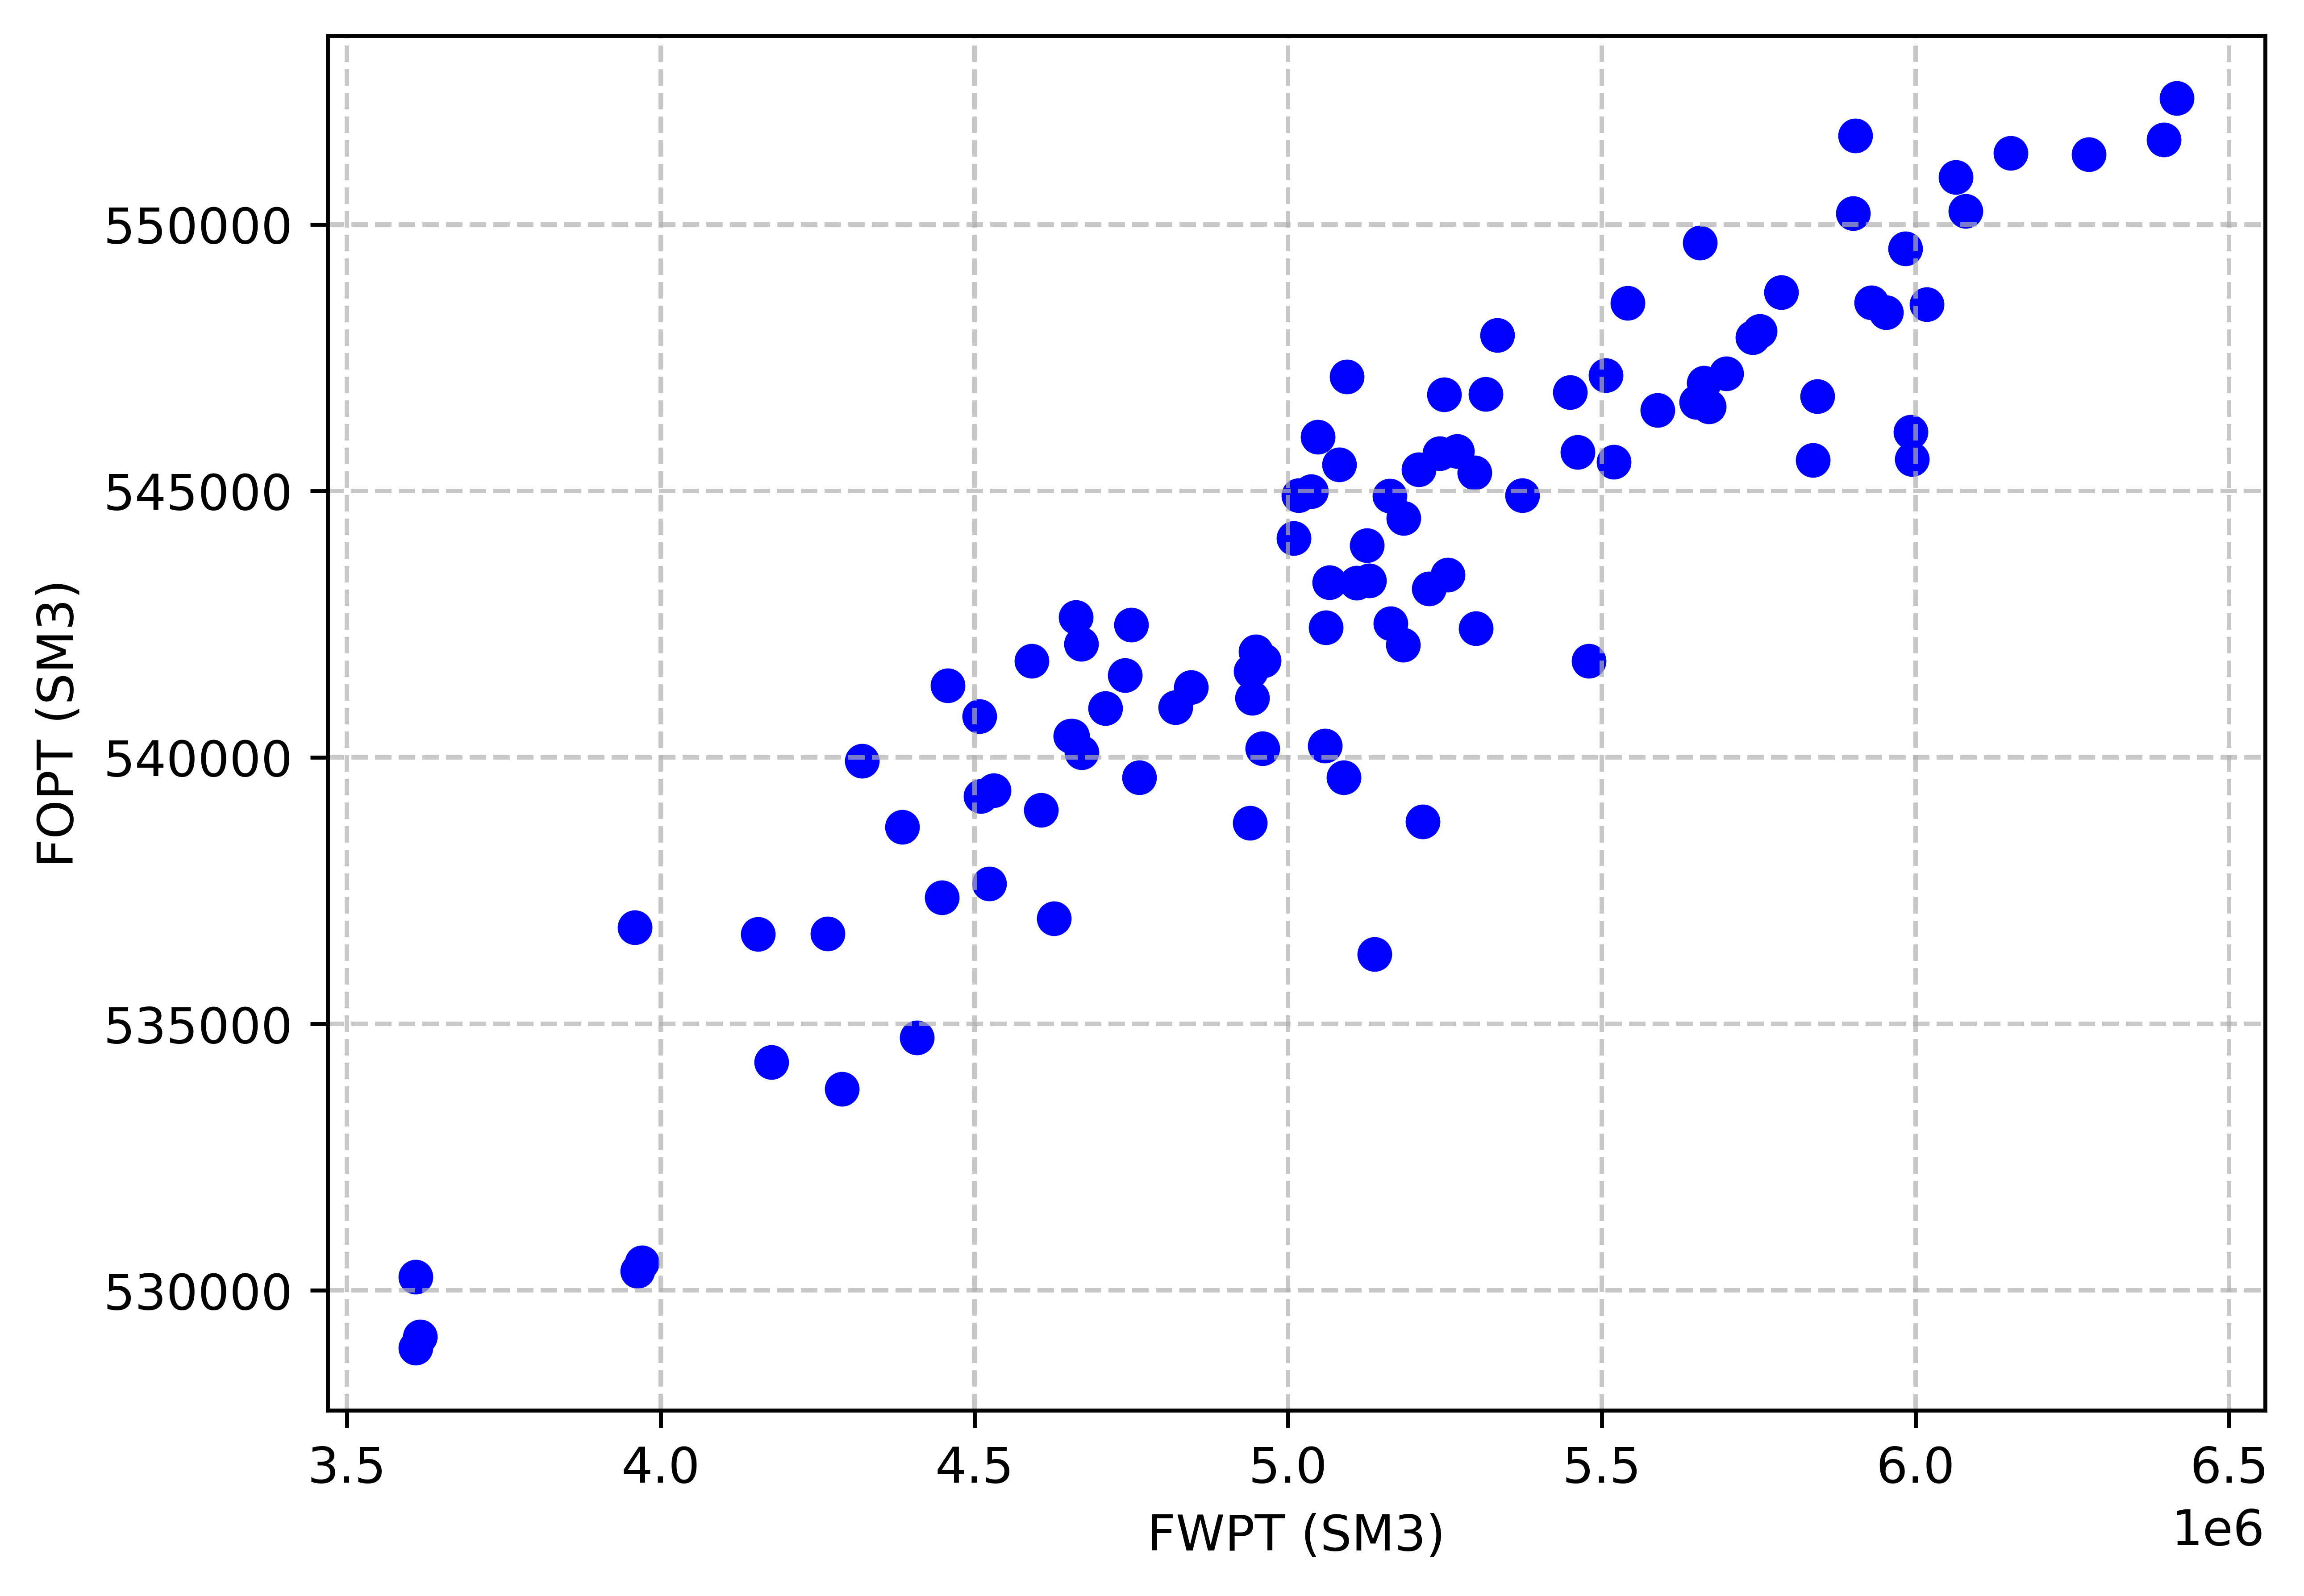

In [13]:
pareto_trials1 = study.best_trials
fopts1 = [t.values[0] for t in study.trials if t.values is not None]
fwpts1 = [t.values[1] for t in study.trials if t.values is not None]

plt.figure(figsize=(7,5),dpi=800)
plt.scatter(fwpts1, fopts1, c='blue')
plt.xlabel("FWPT (SM3)")
plt.ylabel("FOPT (SM3)")
plt.grid(True, which="major", linestyle="--", linewidth=0.9, alpha=0.7)
plt.grid(True, which="minor", linestyle="--", linewidth=0.5, alpha=0.4)
plt.show()

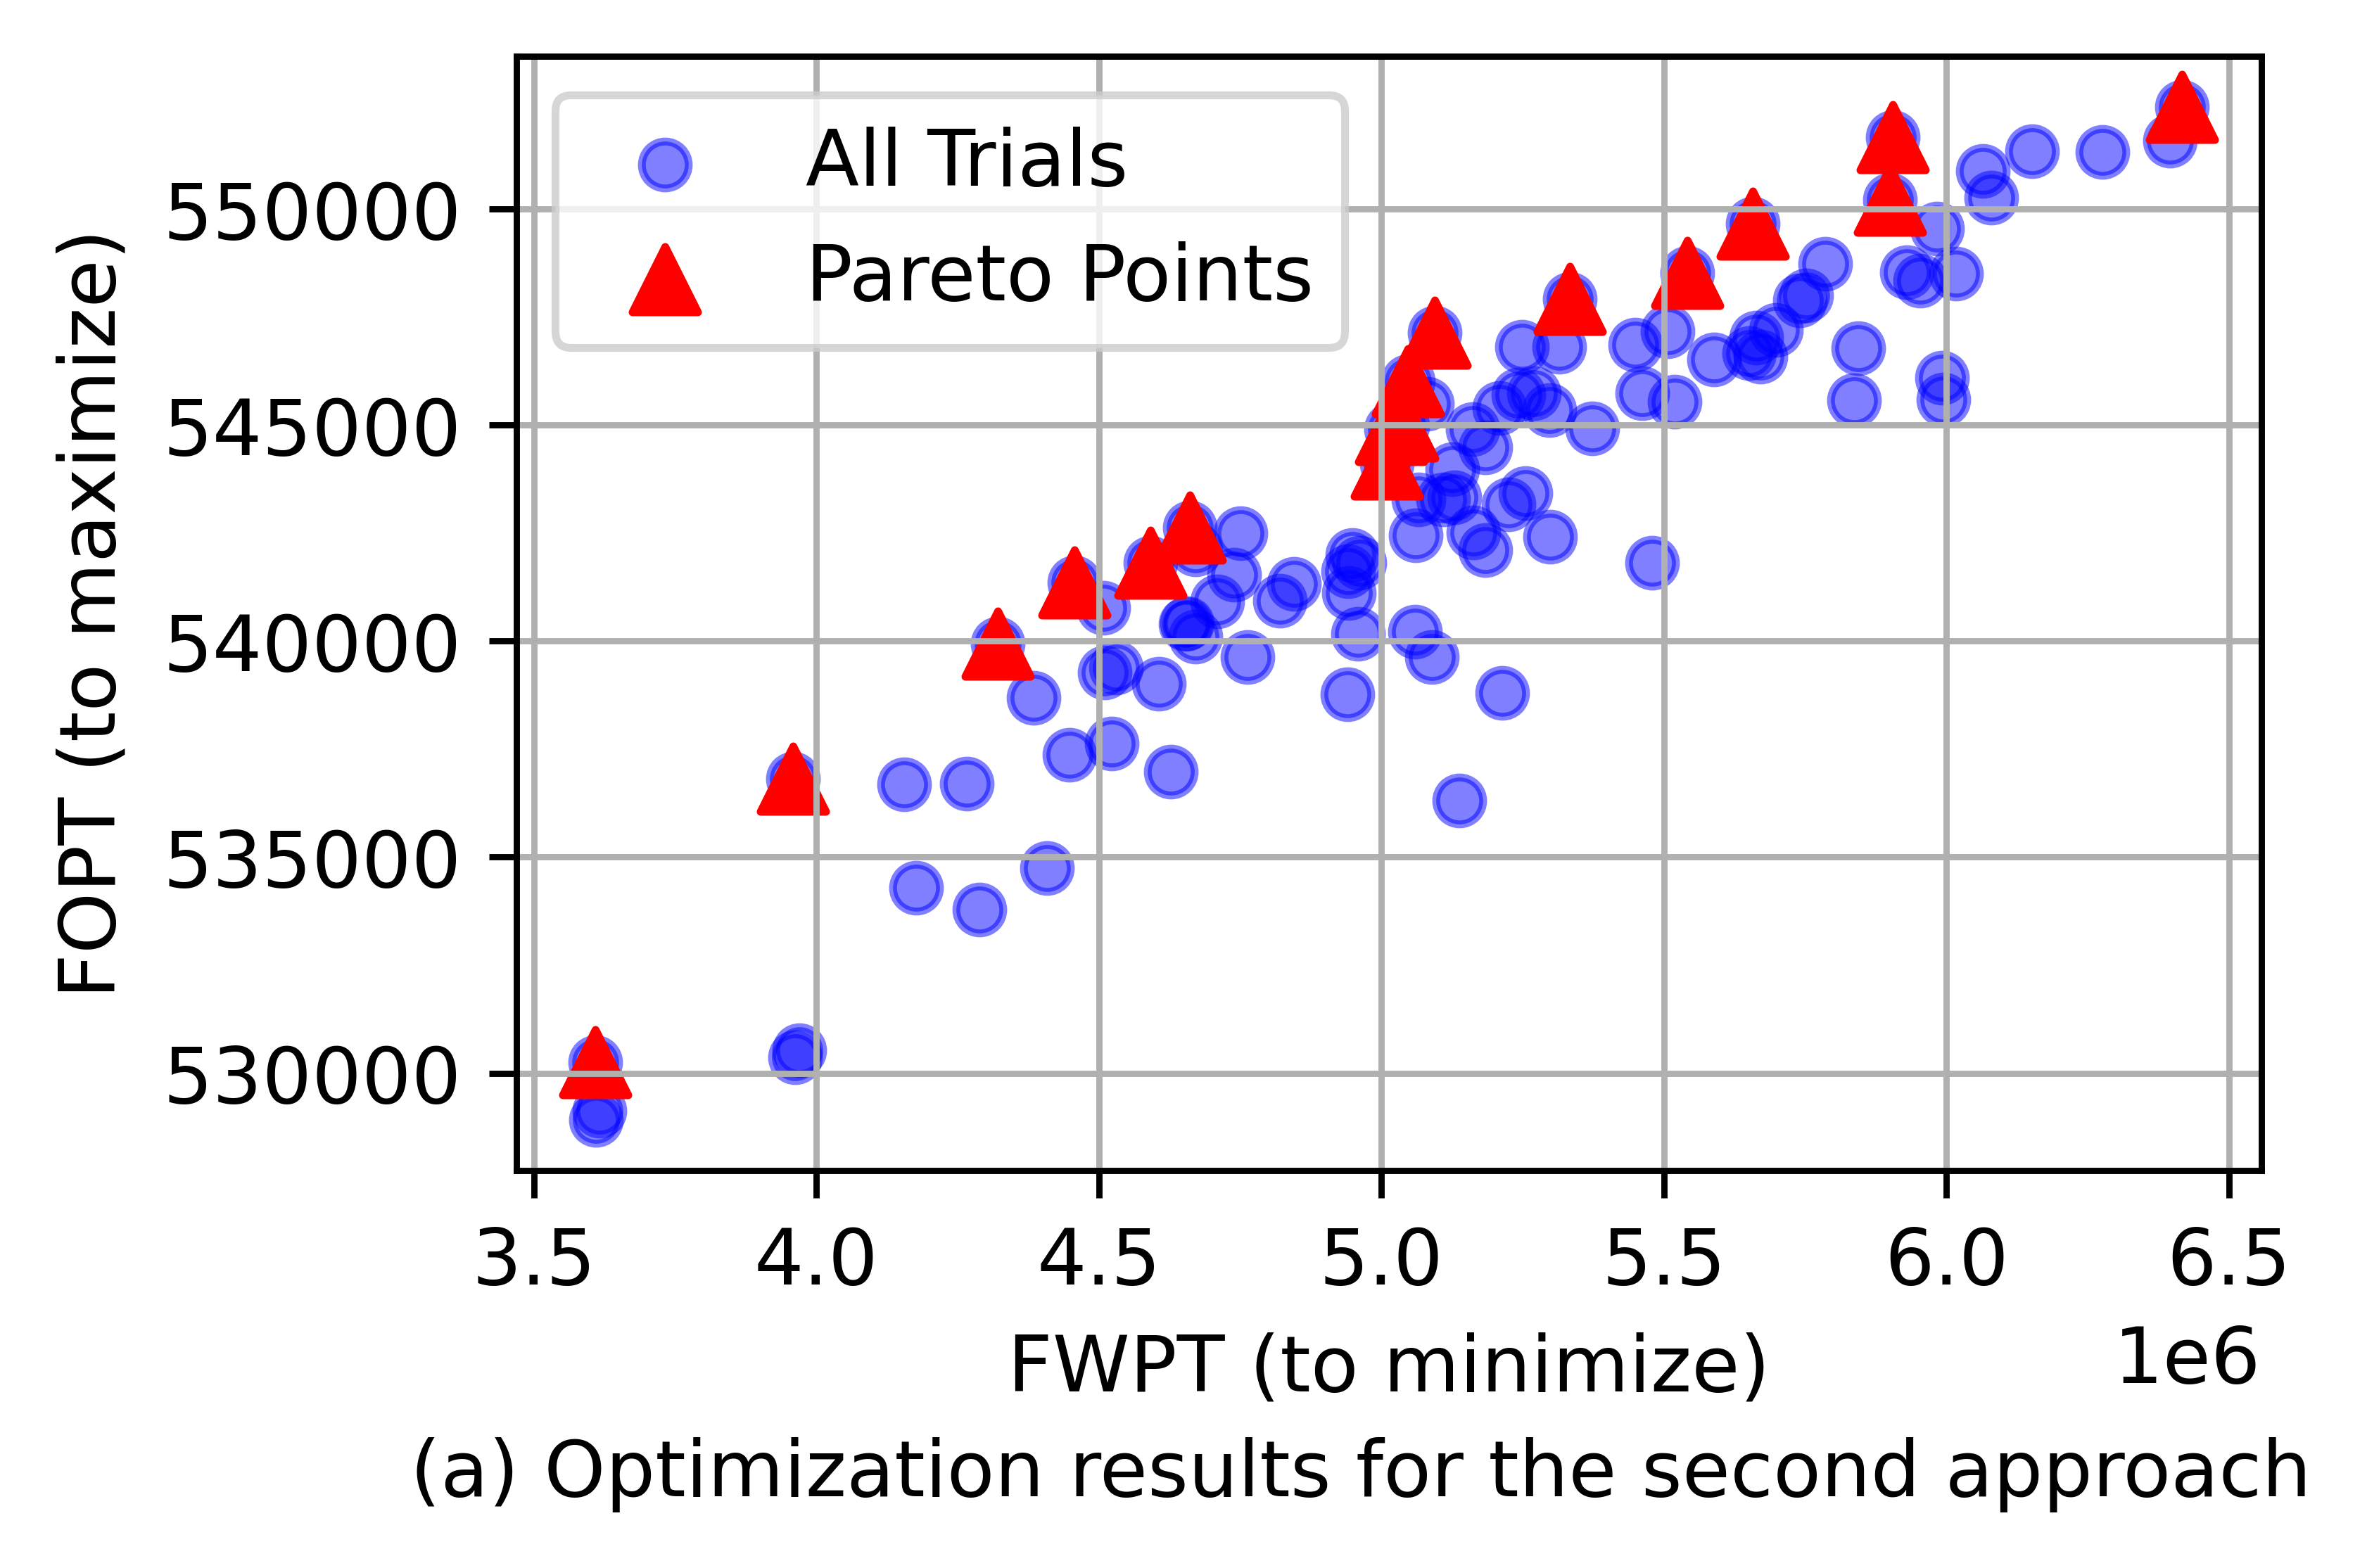

In [21]:
# --- Pareto optimal trials ---
pareto_trials1 = study.best_trials
pareto_fopts = [t.values[0] for t in pareto_trials1]
pareto_fwpts = [t.values[1] for t in pareto_trials1]

# --- Sort Pareto points by FWPT (minimization axis) ---
pareto_points = sorted(zip(pareto_fwpts, pareto_fopts))
pareto_fwpts_sorted, pareto_fopts_sorted = zip(*pareto_points)

# --- All trials ---
fopts = [t.values[0] for t in study.trials if t.values is not None]
fwpts = [t.values[1] for t in study.trials if t.values is not None]

# Create figure
fig, ax = plt.subplots(figsize=(4, 3), dpi=800)

# All solutions
ax.scatter(
    fwpts,
    fopts,
    color='blue',
    alpha=0.5,
    label='All Trials'
)

# Pareto points
ax.scatter(
    pareto_fwpts_sorted,
    pareto_fopts_sorted,
    color='red',
    marker='^',
    s=70,
    label='Pareto Points'
)

# Labels
ax.set_xlabel("FWPT (to minimize)")
ax.set_ylabel("FOPT (to maximize)")

# Legend and grid
ax.legend()
ax.grid(True)

# Leave space for caption
plt.subplots_adjust(bottom=0.22)

# Add caption below the figure
fig.text(
    0.5,
    0.04,
    "(a) Optimization results for the second approach",
    ha="center",
    va="center",
    fontsize=10
)

# Save (optional)
plt.savefig(
    "Optimization_results_second_approach.png",
    dpi=800,
    bbox_inches="tight"
)

plt.show()

# Pareto front optimal results

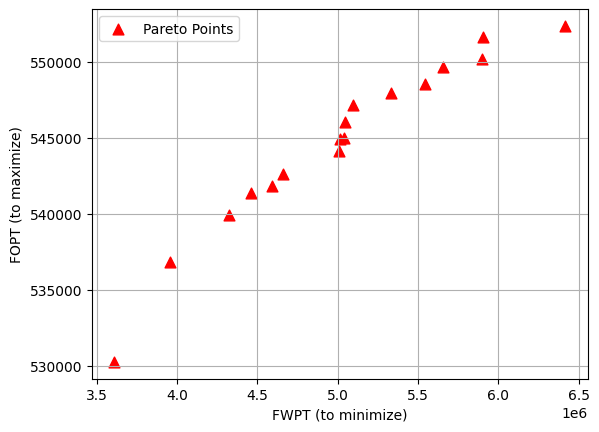

In [22]:
plt.figure()
# Pareto points
plt.scatter(pareto_fwpts_sorted, pareto_fopts_sorted,
            color='red', s=60, label='Pareto Points', marker='^')
plt.xlabel("FWPT (to minimize)")
plt.ylabel("FOPT (to maximize)")
plt.legend()
plt.grid(True)

plt.show()

In [23]:
print("\nPareto Front Table\n")
print("Trial\tFOPT\tFWPT")

for trial in pareto_trials1:
    print(f"{trial.number}\t{trial.values[0]:.2f}\t{trial.values[1]:.2f}")


Pareto Front Table

Trial	FOPT	FWPT
15	552371.30	6416862.00
30	541808.50	4591248.00
35	544913.40	5016852.00
58	530253.00	3609440.00
59	547144.50	5093893.00
61	541353.80	4457296.00
66	544988.90	5036988.00
68	544112.00	5009278.00
70	547923.40	5333197.00
71	546016.60	5047599.00
73	551667.50	5904504.00
74	549654.90	5656807.00
76	550209.60	5900356.00
84	536809.90	3958822.00
86	539933.80	4321026.00
90	548525.30	5541284.00
97	542631.90	4661648.00


In [24]:
# ===============================
# Constraint definition
# ===============================
FWPT_max = 6200000  # constraint on water production

# Extract Pareto values
fopt = np.array([t.values[0] for t in pareto_trials1])
fwpt = np.array([t.values[1] for t in pareto_trials1])

# ===============================
# Apply constraint (FWPT <= limit)
# ===============================
valid_indices = [i for i, fw in enumerate(fwpt) if fw <= FWPT_max]

if valid_indices:

    # Select best FOPT among valid ones
    best_idx = max(valid_indices, key=lambda i: fopt[i])
    best_trial_constraint = pareto_trials1[best_idx]

    # --- Extract values ---
    best_fopt = best_trial_constraint.values[0]
    best_fwpt = best_trial_constraint.values[1]
    params = best_trial_constraint.params

    # --- Separate BHP and Injection rates ---
    bhp_params = {k: v for k, v in params.items() if "BHP" in k}
    inj_params = {k: v for k, v in params.items() if "inj" in k.lower()}

    # --- Print results ---
    print("========== CONSTRAINED OPTIMAL SOLUTION ==========")
    print(f"Trial Number : {best_trial_constraint.number}")
    print(f"FOPT         : {best_fopt}")
    print(f"FWPT         : {best_fwpt}")

    print("\n--- BHP Parameters ---")
    for k, v in bhp_params.items():
        print(f"{k}: {v}")

    print("\n--- Injection Rate Parameters ---")
    for k, v in inj_params.items():
        print(f"{k}: {v}")

else:
    print("No Pareto solution satisfies the FWPT constraint.")

========== CONSTRAINED OPTIMAL SOLUTION ==========
Trial Number : 73
FOPT         : 551667.5
FWPT         : 5904504.0

--- BHP Parameters ---
BHP1_b1: 301
BHP2_b1: 298
BHP3_b1: 255
BHP4_b1: 352
BHP1_b2: 207
BHP2_b2: 353
BHP3_b2: 164
BHP4_b2: 355
BHP1_b3: 262
BHP2_b3: 355
BHP3_b3: 218
BHP4_b3: 340
BHP1_b4: 324
BHP2_b4: 367
BHP3_b4: 367
BHP4_b4: 281
BHP1_b5: 390
BHP2_b5: 343
BHP3_b5: 259
BHP4_b5: 371
BHP1_b6: 191
BHP2_b6: 261
BHP3_b6: 381
BHP4_b6: 272
BHP1_b7: 257
BHP2_b7: 211
BHP3_b7: 205
BHP4_b7: 200
BHP1_b8: 165
BHP2_b8: 241
BHP3_b8: 303
BHP4_b8: 234
BHP1_b9: 346
BHP2_b9: 277
BHP3_b9: 157
BHP4_b9: 170
BHP1_b10: 198
BHP2_b10: 379
BHP3_b10: 375
BHP4_b10: 169

--- Injection Rate Parameters ---
inj_rate1_b1: 315
inj_rate2_b1: 328
inj_rate3_b1: 261
inj_rate4_b1: 91
inj_rate5_b1: 113
inj_rate6_b1: 225
inj_rate7_b1: 400
inj_rate8_b1: 325
inj_rate1_b2: 140
inj_rate2_b2: 331
inj_rate3_b2: 52
inj_rate4_b2: 89
inj_rate5_b2: 389
inj_rate6_b2: 171
inj_rate7_b2: 164
inj_rate8_b2: 312
inj_rate1_b3: 

In [25]:
pareto_numbers = {t.number for t in study.best_trials}

df = pd.DataFrame([
    {
        "Trial": t.number,
        "FOPT": t.values[0],
        "FWPT": t.values[1],
        "Pareto": t.number in pareto_numbers
    }
    for t in study.trials
    if t.values is not None
])

df.to_csv("results_1year.csv", index=False)